In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

# 3 data qubits, 2 ancillas, 2 classical bits
qc = QuantumCircuit(5, 2)

# Prepare logical |1> and encode it as |111>
qc.x(0)
qc.cx(0, 1)
qc.cx(0, 2)

# Inject a bit-flip error on data qubit 1
qc.x(1)

# First parity check: q0 XOR q1
qc.cx(0, 3)
qc.cx(1, 3)

# Second parity check: q0 XOR q2
qc.cx(0, 4)
qc.cx(2, 4)

# Measure the ancillas
qc.measure(3, 0)
qc.measure(4, 1)

print(qc.draw())

simulator = AerSimulator()
compiled = transpile(qc, simulator)

result = simulator.run(
    compiled, shots=1000
).result()

print("Syndrome:", result.get_counts())

     ┌───┐                                         
q_0: ┤ X ├──■────■─────────■─────────■─────────────
     └───┘┌─┴─┐  │  ┌───┐  │         │             
q_1: ─────┤ X ├──┼──┤ X ├──┼────■────┼─────────────
          └───┘┌─┴─┐└───┘  │    │    │             
q_2: ──────────┤ X ├───────┼────┼────┼────■────────
               └───┘     ┌─┴─┐┌─┴─┐  │    │  ┌─┐   
q_3: ────────────────────┤ X ├┤ X ├──┼────┼──┤M├───
                         └───┘└───┘┌─┴─┐┌─┴─┐└╥┘┌─┐
q_4: ──────────────────────────────┤ X ├┤ X ├─╫─┤M├
                                   └───┘└───┘ ║ └╥┘
c: 2/═════════════════════════════════════════╩══╩═
                                              0  1 
Syndrome: {'01': 1000}


In [2]:
# Number of data qubits
n_data = 9

# X-type stabilizer supports
x_checks = [
    [0, 1, 3, 4],
    [2, 5],
    [3, 6],
    [4, 5, 7, 8]
]

# Z-type stabilizer supports
z_checks = [
    [0, 1],
    [1, 2, 4, 5],
    [3, 4, 6, 7],
    [7, 8]
]

print("Number of data qubits:", n_data)
print("Number of X checks:", len(x_checks))
print("Number of Z checks:", len(z_checks))

print("\nX-type stabilizers:")
for i, support in enumerate(x_checks):
    print(f"X{i}: acts on data qubits {support}")

print("\nZ-type stabilizers:")
for i, support in enumerate(z_checks):
    print(f"Z{i}: acts on data qubits {support}")

Number of data qubits: 9
Number of X checks: 4
Number of Z checks: 4

X-type stabilizers:
X0: acts on data qubits [0, 1, 3, 4]
X1: acts on data qubits [2, 5]
X2: acts on data qubits [3, 6]
X3: acts on data qubits [4, 5, 7, 8]

Z-type stabilizers:
Z0: acts on data qubits [0, 1]
Z1: acts on data qubits [1, 2, 4, 5]
Z2: acts on data qubits [3, 4, 6, 7]
Z3: acts on data qubits [7, 8]


In [3]:
print("\nChecking X-Z commutation:")

valid = True

for i, x_support in enumerate(x_checks):
    for j, z_support in enumerate(z_checks):

        # Count shared data qubits
        overlap = set(x_support) & set(z_support)

        # They commute if overlap size is even
        commute = len(overlap) % 2 == 0

        print(
            f"X{i} vs Z{j}: "
            f"overlap={sorted(overlap)}, "
            f"commute={commute}"
        )

        if not commute:
            valid = False

print("\nAll X-Z checks commute:", valid)


Checking X-Z commutation:
X0 vs Z0: overlap=[0, 1], commute=True
X0 vs Z1: overlap=[1, 4], commute=True
X0 vs Z2: overlap=[3, 4], commute=True
X0 vs Z3: overlap=[], commute=True
X1 vs Z0: overlap=[], commute=True
X1 vs Z1: overlap=[2, 5], commute=True
X1 vs Z2: overlap=[], commute=True
X1 vs Z3: overlap=[], commute=True
X2 vs Z0: overlap=[], commute=True
X2 vs Z1: overlap=[], commute=True
X2 vs Z2: overlap=[3, 6], commute=True
X2 vs Z3: overlap=[], commute=True
X3 vs Z0: overlap=[], commute=True
X3 vs Z1: overlap=[4, 5], commute=True
X3 vs Z2: overlap=[4, 7], commute=True
X3 vs Z3: overlap=[7, 8], commute=True

All X-Z checks commute: True


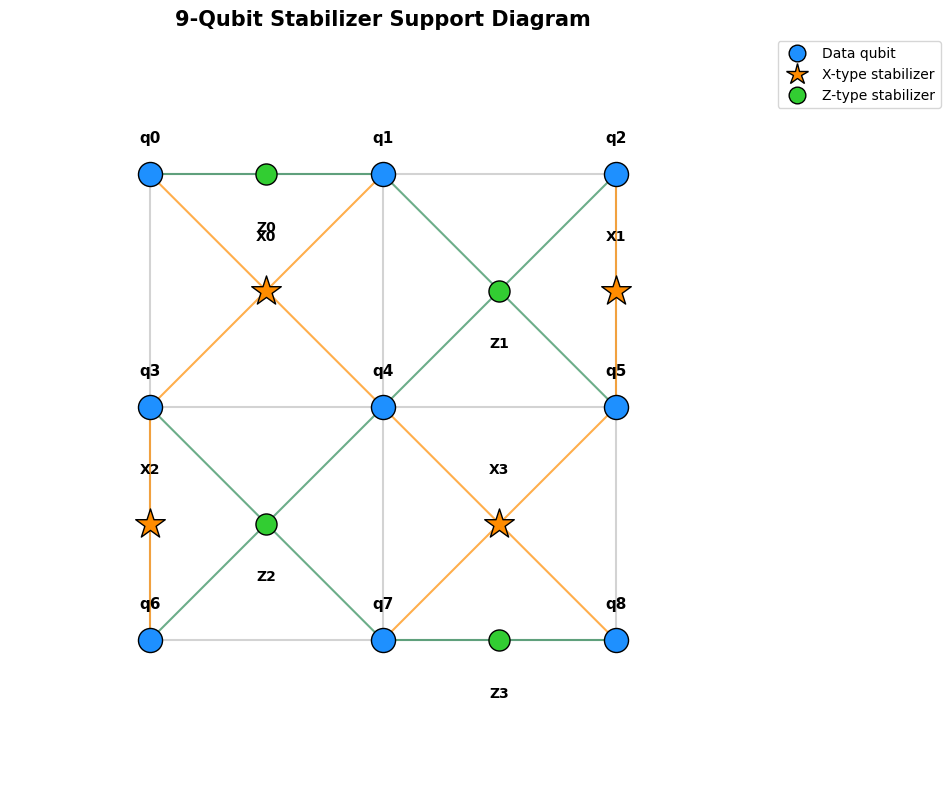

In [4]:

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Number of data qubits
n_data = 9

# X-type stabilizer supports
x_checks = [
    [0, 1, 3, 4],
    [2, 5],
    [3, 6],
    [4, 5, 7, 8]
]

# Z-type stabilizer supports
z_checks = [
    [0, 1],
    [1, 2, 4, 5],
    [3, 4, 6, 7],
    [7, 8]
]

# --------------------------------------------------
# 1. Assign positions to the 9 data qubits
# --------------------------------------------------
# q0 q1 q2
# q3 q4 q5
# q6 q7 q8

positions = {
    0: (0, 2),
    1: (1, 2),
    2: (2, 2),
    3: (0, 1),
    4: (1, 1),
    5: (2, 1),
    6: (0, 0),
    7: (1, 0),
    8: (2, 0)
}

fig, ax = plt.subplots(figsize=(10, 8))

# --------------------------------------------------
# 2. Draw the data-qubit grid
# --------------------------------------------------
for q1 in range(n_data):
    x1, y1 = positions[q1]

    for q2 in range(q1 + 1, n_data):
        x2, y2 = positions[q2]

        # Connect nearest horizontal neighbours
        if y1 == y2 and abs(x1 - x2) == 1:
            ax.plot([x1, x2], [y1, y2],
                    color="lightgray", linewidth=1.5,
                    zorder=1)

        # Connect nearest vertical neighbours
        if x1 == x2 and abs(y1 - y2) == 1:
            ax.plot([x1, x2], [y1, y2],
                    color="lightgray", linewidth=1.5,
                    zorder=1)

# --------------------------------------------------
# 3. Draw X-type stabilizers as orange stars
# --------------------------------------------------
for i, support in enumerate(x_checks):
    xs = [positions[q][0] for q in support]
    ys = [positions[q][1] for q in support]

    # Stabilizer symbol at the centre of its support
    sx = sum(xs) / len(xs)
    sy = sum(ys) / len(ys)

    # Connect the stabilizer to its data qubits
    for q in support:
        x, y = positions[q]
        ax.plot([sx, x], [sy, y],
                color="darkorange", alpha=0.7,
                linewidth=1.5, zorder=2)

    ax.scatter(sx, sy, marker="*",
               s=500, color="darkorange",
               edgecolor="black", zorder=4)

    ax.text(sx, sy + 0.20, f"X{i}",
            ha="center", va="bottom",
            fontsize=10, fontweight="bold")

# --------------------------------------------------
# 4. Draw Z-type stabilizers as green dots
# --------------------------------------------------
for i, support in enumerate(z_checks):
    xs = [positions[q][0] for q in support]
    ys = [positions[q][1] for q in support]

    sx = sum(xs) / len(xs)
    sy = sum(ys) / len(ys)

    # Connect the stabilizer to its data qubits
    for q in support:
        x, y = positions[q]
        ax.plot([sx, x], [sy, y],
                color="seagreen", alpha=0.7,
                linewidth=1.5, zorder=2)

    ax.scatter(sx, sy, marker="o",
               s=230, color="limegreen",
               edgecolor="black", zorder=4)

    ax.text(sx, sy - 0.20, f"Z{i}",
            ha="center", va="top",
            fontsize=10, fontweight="bold")

# --------------------------------------------------
# 5. Draw data qubits on top of the connections
# --------------------------------------------------
for q in range(n_data):
    x, y = positions[q]

    ax.scatter(x, y, s=300, color="dodgerblue",
               edgecolor="black", zorder=5)

    ax.text(x, y + 0.12, f"q{q}",
            ha="center", va="bottom",
            fontsize=11, fontweight="bold")

# --------------------------------------------------
# 6. Add legend, title and formatting
# --------------------------------------------------
legend_items = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="dodgerblue",
           markeredgecolor="black", markersize=12,
           label="Data qubit"),
    Line2D([0], [0], marker="*", color="w",
           markerfacecolor="darkorange",
           markeredgecolor="black", markersize=16,
           label="X-type stabilizer"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="limegreen",
           markeredgecolor="black", markersize=12,
           label="Z-type stabilizer")
]

ax.legend(handles=legend_items, loc="upper left",
          bbox_to_anchor=(1.02, 1))

ax.set_title("9-Qubit Stabilizer Support Diagram",
             fontsize=15, fontweight="bold")

ax.set_aspect("equal")
ax.set_xlim(-0.6, 2.6)
ax.set_ylim(-0.6, 2.6)
ax.axis("off")

plt.tight_layout()
plt.savefig("surface_code_support.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [6]:

# =====================================================
# STEP 1: Calculate the syndrome for a single error
# =====================================================

def calculate_syndrome(error_type, qubit):
    """
    Return the X-check and Z-check syndrome bits.

    X error -> flips Z checks containing the qubit
    Z error -> flips X checks containing the qubit
    Y error -> flips both types
    """

    error_type = error_type.upper()

    if error_type not in ("X", "Y", "Z"):
        raise ValueError("error_type must be X, Y, or Z")

    if not 0 <= qubit < n_data:
        raise ValueError("Invalid data-qubit index")

    # Z checks detect X components of errors
    z_syndrome = [
        int(qubit in support)
        if error_type in ("X", "Y") else 0
        for support in z_checks
    ]

    # X checks detect Z components of errors
    x_syndrome = [
        int(qubit in support)
        if error_type in ("Z", "Y") else 0
        for support in x_checks
    ]

    # Combine both parts into one syndrome signature
    return tuple(x_syndrome + z_syndrome)


# =====================================================
# STEP 2: Build a lookup table for all single-qubit errors
# =====================================================

error_lookup = {}

for q in range(n_data):
    for error_type in ("X", "Y", "Z"):
        syndrome = calculate_syndrome(error_type, q)

        # Keep all candidates in case a syndrome is ambiguous
        error_lookup.setdefault(syndrome, []).append(
            (error_type, q)
        )


# =====================================================
# STEP 3: Inject one error
# =====================================================

error_type = "X"
error_qubit = 2

measured_syndrome = calculate_syndrome(
    error_type, error_qubit
)

print(f"Injected error: {error_type} on q{error_qubit}")

print("X-check syndrome:",
      measured_syndrome[:len(x_checks)])

print("Z-check syndrome:",
      measured_syndrome[len(x_checks):])

Injected error: X on q2
X-check syndrome: (0, 0, 0, 0)
Z-check syndrome: (0, 1, 0, 0)


In [7]:

# =====================================================
# STEP 2: MATHEMATICAL VALIDATION OF THE STABILIZERS
# =====================================================

# 1. Validate that all supports contain valid qubit indices
all_checks = x_checks + z_checks

for i, support in enumerate(all_checks):
    assert len(support) == len(set(support)), (
        f"Duplicate qubit in stabilizer {i}"
    )
    assert all(0 <= q < n_data for q in support), (
        f"Invalid qubit index in stabilizer {i}"
    )

print("PASS: All stabilizer supports have valid qubit indices.")


# 2. Check commutation between every X-check and Z-check
anticommuting_pairs = []

for i, x_support in enumerate(x_checks):
    for j, z_support in enumerate(z_checks):
        overlap = set(x_support) & set(z_support)

        if len(overlap) % 2 != 0:
            anticommuting_pairs.append(
                (i, j, sorted(overlap))
            )

if anticommuting_pairs:
    print("\nFAIL: Some X and Z checks anticommute.")
    for x_id, z_id, overlap in anticommuting_pairs:
        print(
            f"X{x_id} and Z{z_id}: "
            f"overlap = {overlap}"
        )
else:
    print("PASS: Every X-check commutes with every Z-check.")


# 3. Calculate matrix rank over GF(2)
# GF(2) means arithmetic modulo 2.

def binary_rank(checks, n_qubits):
    rows = []

    for support in checks:
        row = [0] * n_qubits
        for q in support:
            row[q] = 1
        rows.append(row)

    pivot_row = 0

    for col in range(n_qubits):
        pivot = next(
            (
                r for r in range(pivot_row, len(rows))
                if rows[r][col] == 1
            ),
            None
        )

        if pivot is None:
            continue

        rows[pivot_row], rows[pivot] = (
            rows[pivot], rows[pivot_row]
        )

        for r in range(len(rows)):
            if r != pivot_row and rows[r][col] == 1:
                rows[r] = [
                    a ^ b
                    for a, b in zip(
                        rows[r], rows[pivot_row]
                    )
                ]

        pivot_row += 1

        if pivot_row == len(rows):
            break

    return pivot_row


rank_x = binary_rank(x_checks, n_data)
rank_z = binary_rank(z_checks, n_data)

# Only interpret k if the stabilizers commute.
if not anticommuting_pairs:
    k = n_data - rank_x - rank_z

    print("\n--- Stabilizer rank results ---")
    print("Number of data qubits:", n_data)
    print("Number of X checks:", len(x_checks))
    print("Independent X checks:", rank_x)
    print("Number of Z checks:", len(z_checks))
    print("Independent Z checks:", rank_z)
    print("Total independent checks:", rank_x + rank_z)
    print("Encoded logical qubits k =", k)

    if k < 0:
        print("FAIL: Check the stabilizer definitions.")
    elif k == 1:
        print("The stabilizer ranks are consistent with 1 logical qubit.")
    else:
        print(f"The stabilizer ranks imply {k} logical qubits.")
else:
    print("\nDo not infer the encoded qubit count yet.")
    print("Fix the anticommuting stabilizers first.")


PASS: All stabilizer supports have valid qubit indices.
PASS: Every X-check commutes with every Z-check.

--- Stabilizer rank results ---
Number of data qubits: 9
Number of X checks: 4
Independent X checks: 4
Number of Z checks: 4
Independent Z checks: 4
Total independent checks: 8
Encoded logical qubits k = 1
The stabilizer ranks are consistent with 1 logical qubit.


In [8]:

import numpy as np

# Convert a list of stabilizer supports into a binary matrix
def make_matrix(checks, n):
    H = np.zeros((len(checks), n), dtype=np.uint8)
    for i, support in enumerate(checks):
        H[i, support] = 1
    return H


# Gaussian elimination over GF(2)
def rref_gf2(A):
    A = np.array(A, dtype=np.uint8).copy()
    rows, cols = A.shape
    pivot_cols = []
    r = 0

    for c in range(cols):
        pivots = np.where(A[r:, c] == 1)[0]
        if len(pivots) == 0:
            continue

        p = r + pivots[0]
        A[[r, p]] = A[[p, r]]

        for i in range(rows):
            if i != r and A[i, c]:
                A[i] ^= A[r]

        pivot_cols.append(c)
        r += 1

        if r == rows:
            break

    return A, pivot_cols


# Find a basis for the nullspace of A over GF(2)
def nullspace_gf2(A):
    R, pivots = rref_gf2(A)
    n = A.shape[1]
    free_cols = [c for c in range(n) if c not in pivots]
    basis = []

    for free in free_cols:
        v = np.zeros(n, dtype=np.uint8)
        v[free] = 1

        for row, pivot in enumerate(pivots):
            v[pivot] = R[row, free]

        basis.append(v)

    return basis


# Check if v belongs to the row space of A
def in_rowspace(A, v):
    before = len(A)
    after = len(rref_gf2(np.vstack([A, v]))[1])
    return before == after


Hx = make_matrix(x_checks, n_data)
Hz = make_matrix(z_checks, n_data)

# An X-type logical operator must commute with all Z checks.
x_candidates = nullspace_gf2(Hz)

logical_x = next(
    (v for v in x_candidates if not in_rowspace(Hx, v)),
    None
)

# A Z-type logical operator must commute with all X checks.
z_candidates = nullspace_gf2(Hx)

logical_z = None

if logical_x is not None:
    for v in z_candidates:
        if not in_rowspace(Hz, v):
            # X_L and Z_L must anticommute:
            # their supports must overlap oddly.
            if int(np.dot(logical_x, v) % 2) == 1:
                logical_z = v
                break


# Display results
if logical_x is None:
    print("No nontrivial X logical operator found.")
elif logical_z is None:
    print("Found X_L, but did not find a paired Z_L.")
else:
    x_support = np.flatnonzero(logical_x).tolist()
    z_support = np.flatnonzero(logical_z).tolist()

    print("Logical X_L support:", x_support)
    print("Logical Z_L support:", z_support)
    print("Weight of X_L:", len(x_support))
    print("Weight of Z_L:", len(z_support))
    print(
        "Overlap:",
        len(set(x_support) & set(z_support))
    )
    print("Logical operators anticommute: YES")


Logical X_L support: [0, 1, 2]
Logical Z_L support: [0, 3, 6]
Weight of X_L: 3
Weight of Z_L: 3
Overlap: 1
Logical operators anticommute: YES


In [9]:

from itertools import combinations

def find_minimum_logical_weight(check_matrix, stabilizer_matrix,
                                n_qubits, max_weight=7):
    """
    Find the smallest nontrivial logical operator of one Pauli type.
    Returns its weight and one support, or None if not found
    within max_weight.
    """
    for weight in range(1, max_weight + 1):
        for support in combinations(range(n_qubits), weight):
            v = np.zeros(n_qubits, dtype=np.uint8)
            v[list(support)] = 1

            # Commutes with all checks of the opposite Pauli type
            if np.any((check_matrix @ v) % 2):
                continue

            # Must not be a product of same-type stabilizers
            if in_rowspace(stabilizer_matrix, v):
                continue

            return weight, list(support)

    return None


# X logicals commute with Z checks and must not be X stabilizers.
min_x = find_minimum_logical_weight(
    Hz, Hx, n_data, max_weight=7
)

# Z logicals commute with X checks and must not be Z stabilizers.
min_z = find_minimum_logical_weight(
    Hx, Hz, n_data, max_weight=7
)

print("Minimum X-logical found:", min_x)
print("Minimum Z-logical found:", min_z)

if min_x is not None and min_z is not None:
    print("CSS code distance:", min(min_x[0], min_z[0]))
else:
    print("At least one minimum was not found within weight 7.")


Minimum X-logical found: (3, [0, 1, 2])
Minimum Z-logical found: (3, [0, 3, 6])
CSS code distance: 3
